# Member 1 (Boon Yun Nee) - Personal Notebook
**Course:** 6001CMD Machine Learning & Related Applications  
**Group:** Group 13  
**Components Owned:**
- **Part B:** Exploratory Data Analysis (EDA) - Descriptive Statistics, Target Imbalance, Distributions & Outliers, Feature Correlation, Categorical Drivers
- **Part D & E:** Base Model 1 - Logistic Regression (Baseline, 5-Fold Stratified CV, GridSearchCV Hyperparameter Tuning, L1 Sparsity, Test Evaluation)


## 1. Setup & Environment Verification

In [1]:
import sys
import pathlib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Set project root to path
PROJECT_ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from modules.shared.utils import (
    get_data,
    build_pipeline,
    CV,
    SCORING,
    RANDOM_STATE,
    save_results
)

print(f"Project root: {PROJECT_ROOT}")


Project root: c:\Users\ASUS\GroupMachineLearning


## 2. Load Processed Dataset (Contract Verification)

In [2]:
X_train, X_test, y_train, y_test = get_data()
print(f"X_train shape: {X_train.shape} | X_test shape: {X_test.shape}")
print(f"y_train churn distribution:\n{y_train.value_counts(normalize=True).round(4)}")
print(f"y_test churn distribution:\n{y_test.value_counts(normalize=True).round(4)}")


X_train shape: (5616, 25) | X_test shape: (1405, 25)
y_train churn distribution:
Churn
0    0.7356
1    0.2644
Name: proportion, dtype: float64
y_test churn distribution:
Churn
0    0.7352
1    0.2648
Name: proportion, dtype: float64


## 3. Part B: Exploratory Data Analysis (EDA)
Examining the raw dataset distribution, target class imbalance, numerical outlier profiles, correlation matrix, and key categorical drivers.


In [3]:
# Load raw dataset for EDA exploration
raw_path = PROJECT_ROOT / "data" / "raw" / "WA_Fn-UseC_-Telco-Customer-Churn.csv"
df_raw = pd.read_csv(raw_path)

# Handle blank spaces in TotalCharges for EDA
df_raw['TotalCharges'] = pd.to_numeric(df_raw['TotalCharges'], errors='coerce').fillna(0.0)

print(f"Raw shape: {df_raw.shape}")
df_raw.head()


Raw shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### 3.1 Descriptive Statistics (Table 1 in Report)

In [4]:
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
stats_df = df_raw[num_cols].describe(percentiles=[0.25, 0.5, 0.75]).T
stats_df['skewness'] = df_raw[num_cols].skew()
stats_df['kurtosis'] = df_raw[num_cols].kurt()
stats_df[['mean', 'std', 'min', '25%', '50%', '75%', 'max', 'skewness', 'kurtosis']].round(3)


,mean,std,min,25%,50%,75%,max,skewness,kurtosis
tenure,32.371,24.559,0.00,9.00,29.00,55.00,72.00,0.240,-1.387
MonthlyCharges,64.762,30.090,18.25,35.50,70.35,89.85,118.75,-0.221,-1.257
TotalCharges,2279.734,2266.794,0.00,398.55,1394.55,3786.60,8684.80,0.963,-0.229


### 3.2 Target Variable Distribution (Figure 1)

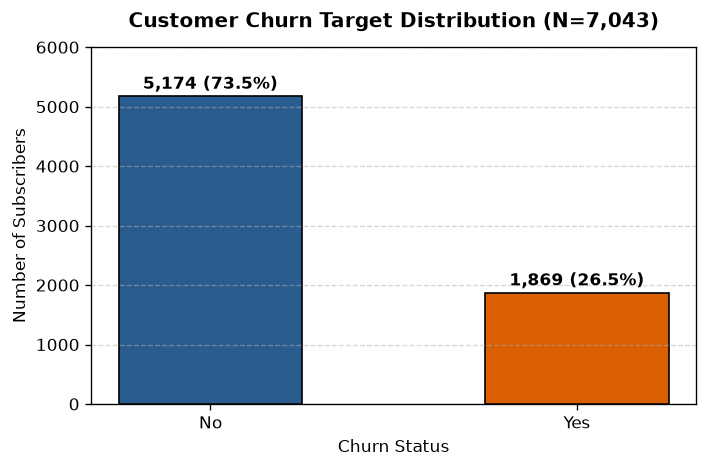

In [5]:
fig, ax = plt.subplots(figsize=(6, 4), dpi=120)
counts = df_raw['Churn'].value_counts()
pcts = df_raw['Churn'].value_counts(normalize=True) * 100

bars = ax.bar(counts.index, counts.values, color=['#2b5c8f', '#d95f02'], width=0.5, edgecolor='black', linewidth=1)
for bar, pct in zip(bars, pcts):
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2.0, yval + 60, f"{int(yval):,} ({pct:.1f}%)", ha='center', va='bottom', fontsize=10, fontweight='bold')

ax.set_title("Customer Churn Target Distribution (N=7,043)", fontsize=12, fontweight='bold', pad=12)
ax.set_xlabel("Churn Status", fontsize=10)
ax.set_ylabel("Number of Subscribers", fontsize=10)
ax.set_ylim(0, 6000)
ax.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


### 3.3 Numerical Feature Distributions & Outliers (Figure 2)

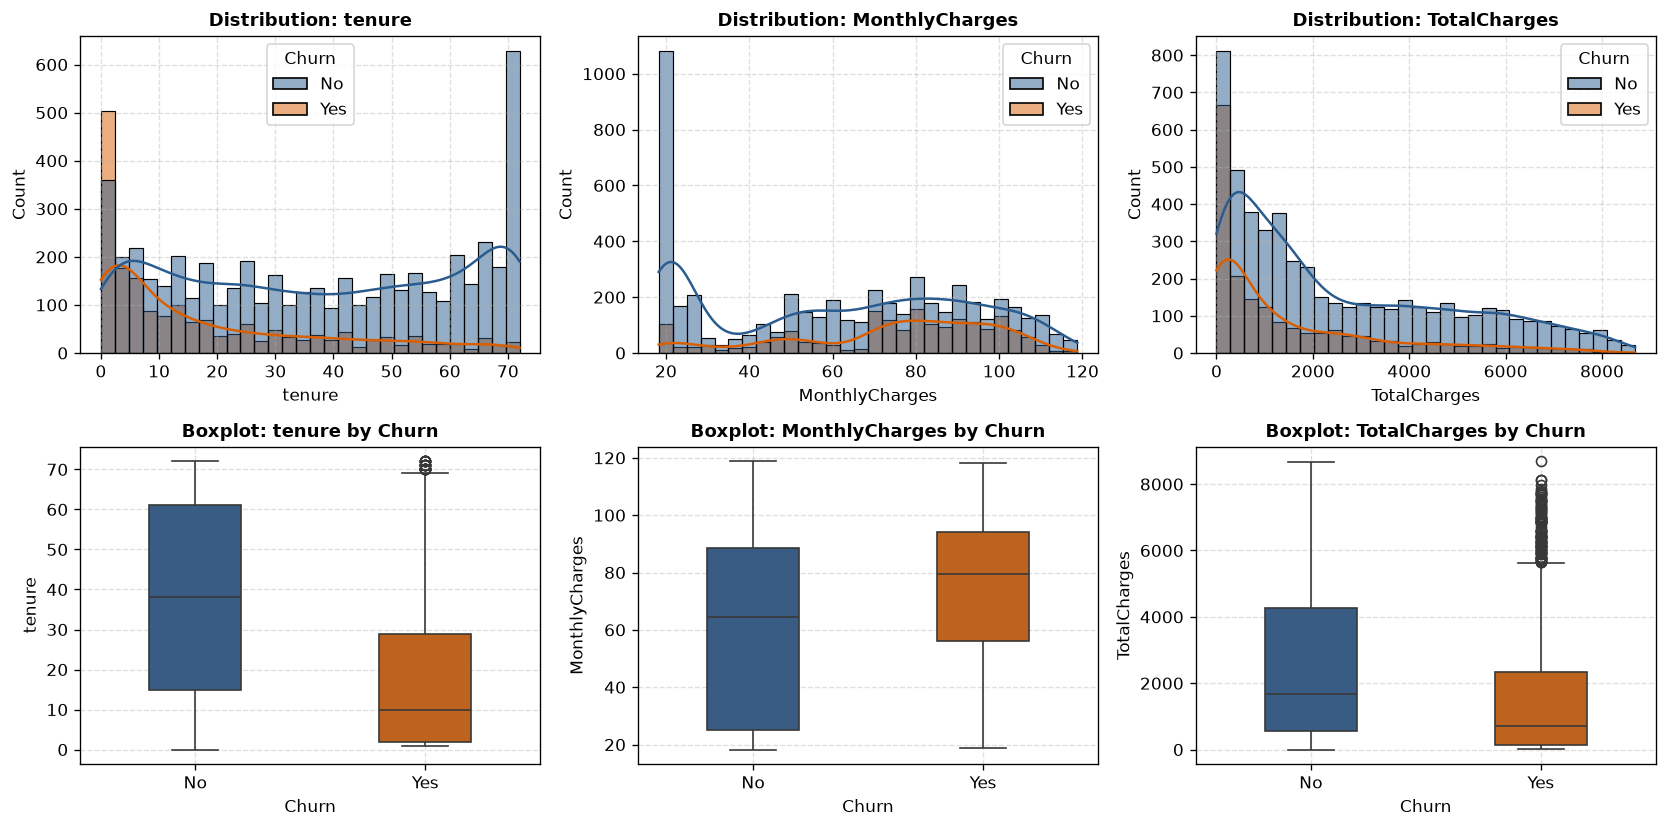

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7), dpi=120)

for i, col in enumerate(num_cols):
    sns.histplot(data=df_raw, x=col, hue='Churn', kde=True, ax=axes[0, i], palette=['#2b5c8f', '#d95f02'], alpha=0.5, bins=30)
    axes[0, i].set_title(f"Distribution: {col}", fontsize=11, fontweight='bold')
    axes[0, i].grid(True, linestyle='--', alpha=0.4)
    
    sns.boxplot(data=df_raw, x='Churn', y=col, ax=axes[1, i], palette=['#2b5c8f', '#d95f02'], width=0.4)
    axes[1, i].set_title(f"Boxplot: {col} by Churn", fontsize=11, fontweight='bold')
    axes[1, i].grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()


### 3.4 Feature Correlation Heatmap (Figure 3)

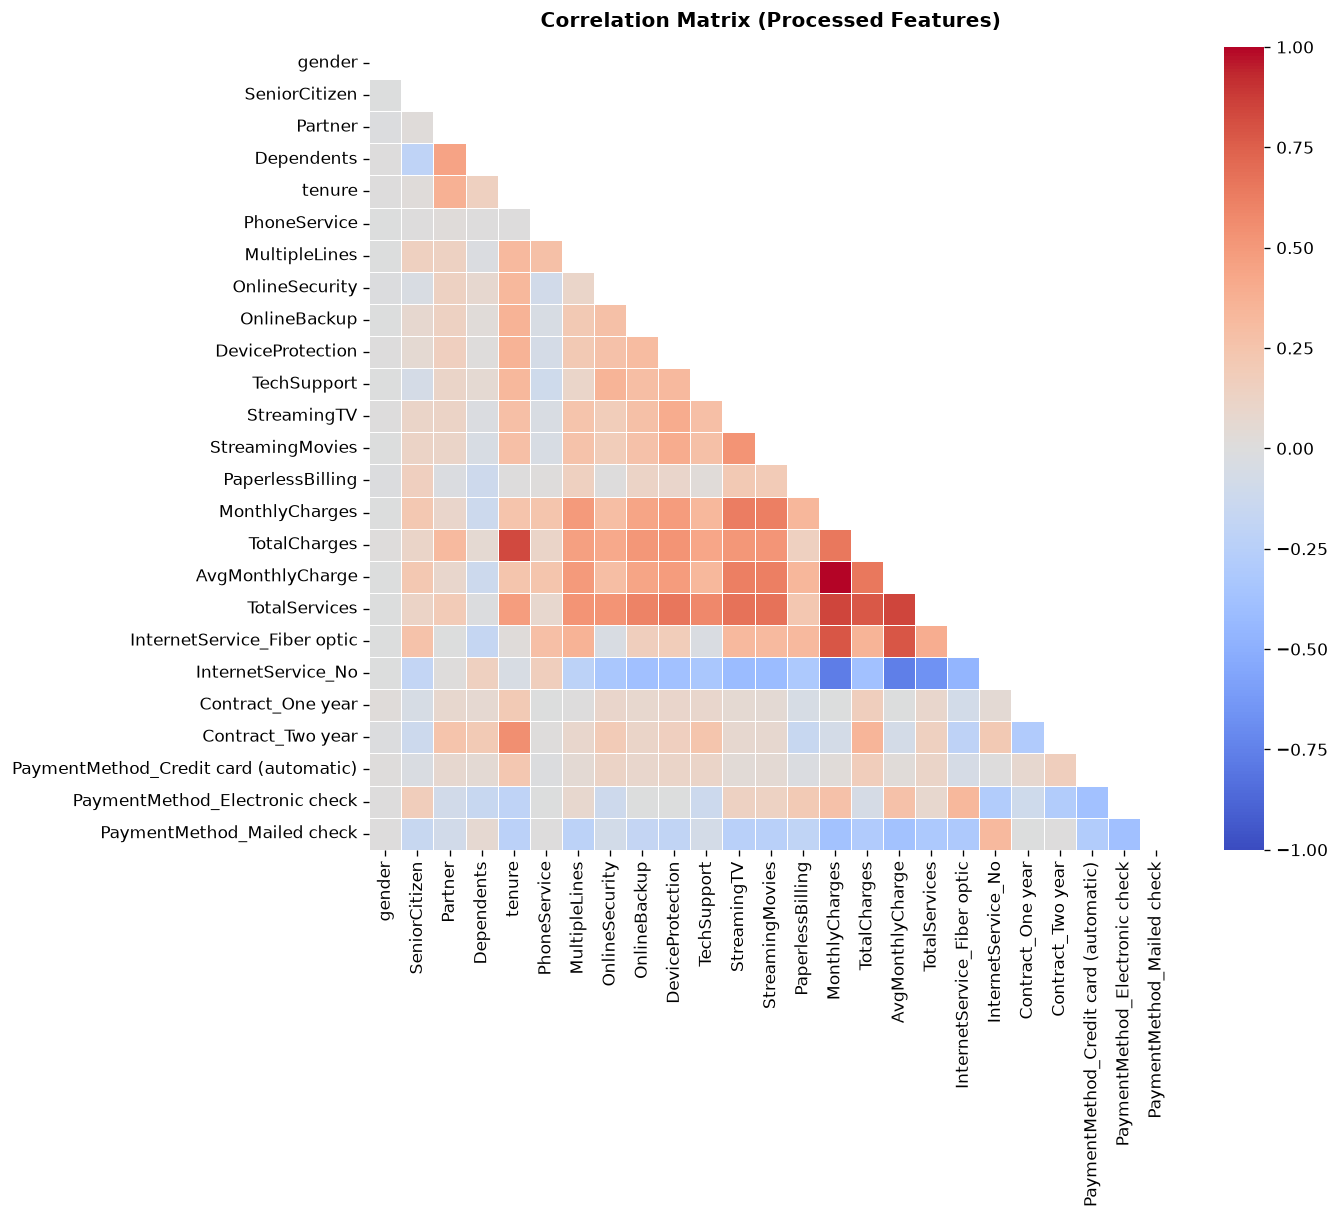

In [7]:
corr = X_train.corr()

plt.figure(figsize=(12, 10), dpi=120)
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, cmap='coolwarm', vmin=-1, vmax=1, center=0, annot=False, square=True, linewidths=0.5)
plt.title("Correlation Matrix (Processed Features)", fontsize=12, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()


### 3.5 Key Categorical Churn Drivers (Figure 4)

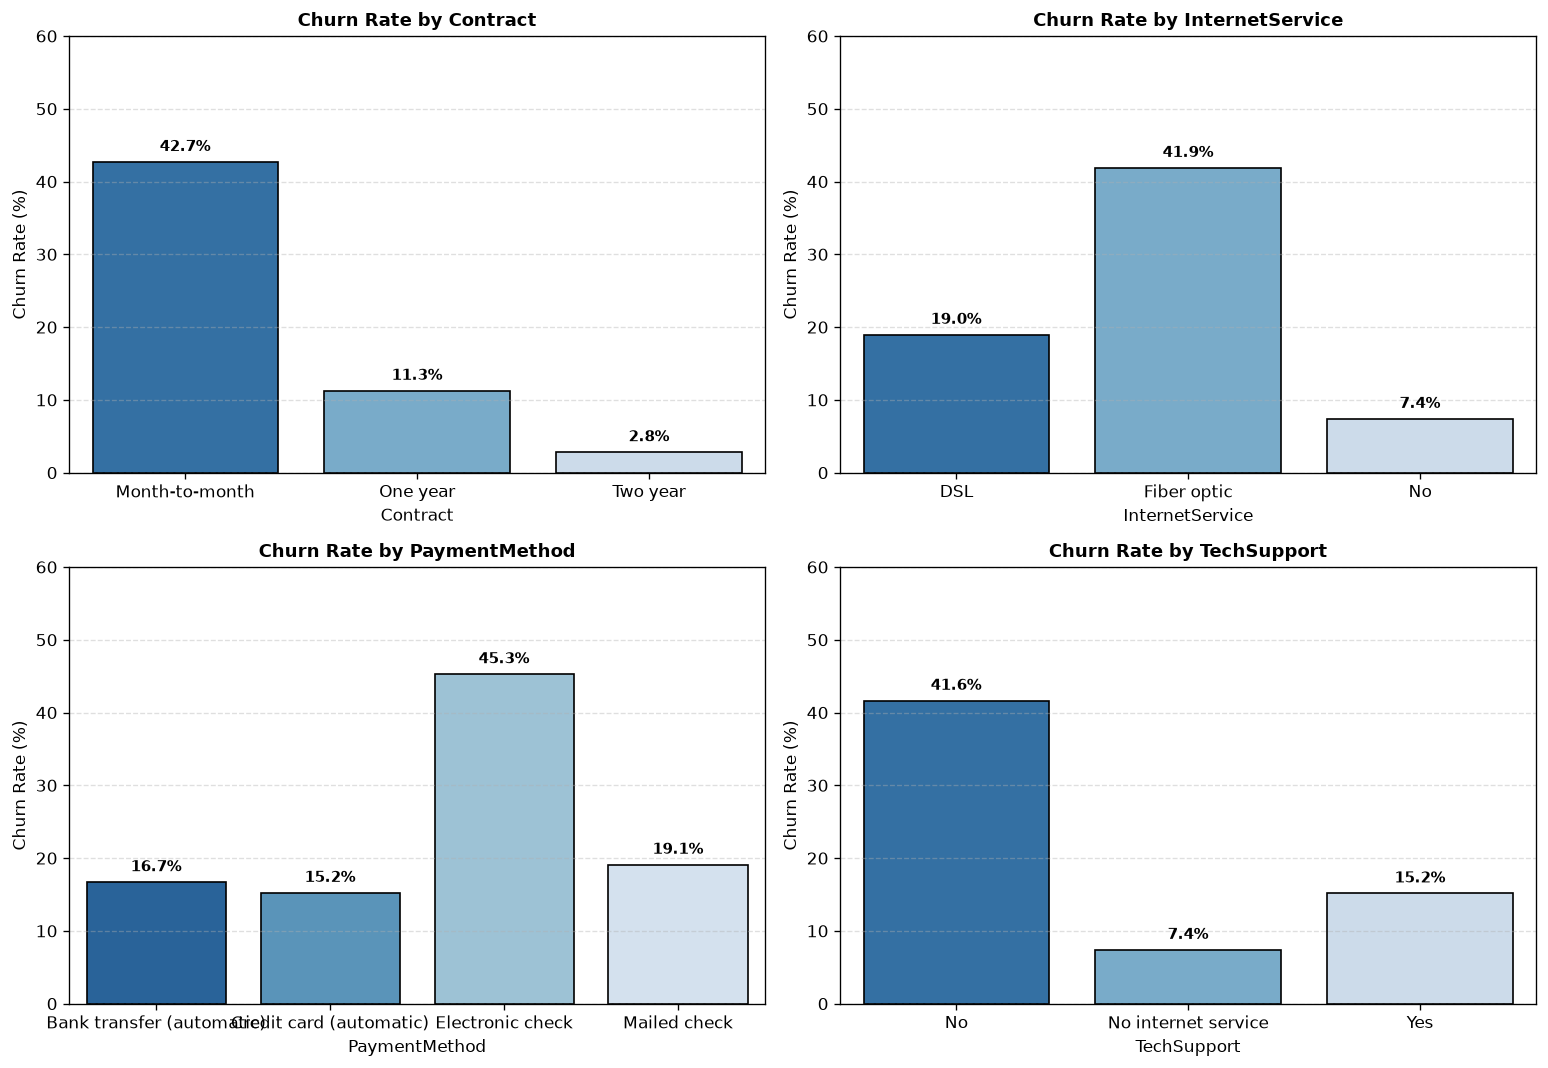

In [8]:
cat_cols = ['Contract', 'InternetService', 'PaymentMethod', 'TechSupport']
fig, axes = plt.subplots(2, 2, figsize=(13, 9), dpi=120)
axes = axes.flatten()

for idx, col in enumerate(cat_cols):
    churn_rate = df_raw.groupby(col)['Churn'].apply(lambda x: (x == 'Yes').mean() * 100).reset_index()
    sns.barplot(data=churn_rate, x=col, y='Churn', ax=axes[idx], palette='Blues_r', edgecolor='black')
    axes[idx].set_title(f"Churn Rate by {col}", fontsize=11, fontweight='bold')
    axes[idx].set_ylabel("Churn Rate (%)")
    axes[idx].set_ylim(0, 60)
    axes[idx].grid(axis='y', linestyle='--', alpha=0.4)
    for p in axes[idx].patches:
        axes[idx].annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width() / 2., p.get_height() + 1),
                           ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()


## 4. Part D & E: Base Model 1 - Logistic Regression
Baseline evaluation, 5-Fold Stratified GridSearchCV hyperparameter tuning, results saving, and feature coefficients analysis.


### 4.1 Define Pipelines & Hyperparameter Search Grid

In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, cross_validate
import time

# 1. Baseline pipeline (Default Logistic Regression wrapped in Scaler -> SMOTE -> Model)
baseline_pipe = build_pipeline(
    LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
)

# 2. Tuned pipeline candidate
tune_pipe = build_pipeline(
    LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
)

param_grid = {
    "model__C": [0.01, 0.1, 1.0, 10.0],
    "model__penalty": ["l1", "l2"],
    "model__solver": ["liblinear"],
}

print(f"Grid search candidates: {param_grid}")


Grid search candidates: {'model__C': [0.01, 0.1, 1.0, 10.0], 'model__penalty': ['l1', 'l2'], 'model__solver': ['liblinear']}


### 4.2 Execute 5-Fold Stratified GridSearchCV

In [10]:
search = GridSearchCV(
    estimator=tune_pipe,
    param_grid=param_grid,
    cv=CV,
    scoring=SCORING,
    refit="f1",
    n_jobs=-1,
    return_train_score=True
)

t0 = time.time()
search.fit(X_train, y_train)
elapsed = time.time() - t0

print(f"GridSearch completed in {elapsed:.2f} seconds.")
print(f"Best Hyperparameters: {search.best_params_}")
print(f"Best 5-Fold CV F1: {search.best_score_:.4f}")


GridSearch completed in 31.99 seconds.
Best Hyperparameters: {'model__C': 0.1, 'model__penalty': 'l1', 'model__solver': 'liblinear'}
Best 5-Fold CV F1: 0.6335


### 4.3 Evaluate Baseline vs Tuned and Save to results/logistic_regression.json

In [11]:
# Standardized save_results utility automatically evaluates baseline + tuned and generates JSON
results = save_results(
    name="logistic_regression",
    baseline_pipe=baseline_pipe,
    search=search,
    X_train=X_train,
    y_train=y_train,
    X_test=X_test,
    y_test=y_test,
)

print("=== BASELINE CV RESULTS ===")
for k, v in results['baseline']['cv'].items():
    print(f"  {k.upper():<10}: {v:.4f} +/- {results['baseline']['cv_std'][k]:.4f}")

print("\n=== TUNED CV RESULTS ===")
for k, v in results['tuned']['cv'].items():
    print(f"  {k.upper():<10}: {v:.4f} +/- {results['tuned']['cv_std'][k]:.4f}")

print("\n=== HELD-OUT TEST PERFORMANCE ===")
for k, v in results['tuned']['test'].items():
    if k != 'confusion_matrix':
        print(f"  {k.upper():<10}: {v:.4f}")

print(f"\nTest Confusion Matrix:\n{np.array(results['tuned']['test']['confusion_matrix'])}")



=== logistic_regression ===
Baseline CV F1 0.6297 | ROC-AUC 0.8452
Tuned    CV F1 0.6335 | ROC-AUC 0.8452
Best params: {'model__C': 0.1, 'model__penalty': 'l1', 'model__solver': 'liblinear'}
Saved -> results\logistic_regression.json
=== BASELINE CV RESULTS ===
  F1        : 0.6297 +/- 0.0202
  ROC_AUC   : 0.8452 +/- 0.0162
  RECALL    : 0.7953 +/- 0.0329
  PRECISION : 0.5213 +/- 0.0146
  ACCURACY  : 0.7528 +/- 0.0120

=== TUNED CV RESULTS ===
  F1        : 0.6335 +/- 0.0207
  ROC_AUC   : 0.8452 +/- 0.0161
  RECALL    : 0.7966 +/- 0.0328
  PRECISION : 0.5259 +/- 0.0149
  ACCURACY  : 0.7564 +/- 0.0123

=== HELD-OUT TEST PERFORMANCE ===
  ACCURACY  : 0.7473
  PRECISION : 0.5155
  RECALL    : 0.7581
  F1        : 0.6137
  ROC_AUC   : 0.8400

Test Confusion Matrix:
[[768 265]
 [ 90 282]]


### 4.4 Feature Weights & L1 Sparsity Interpretation

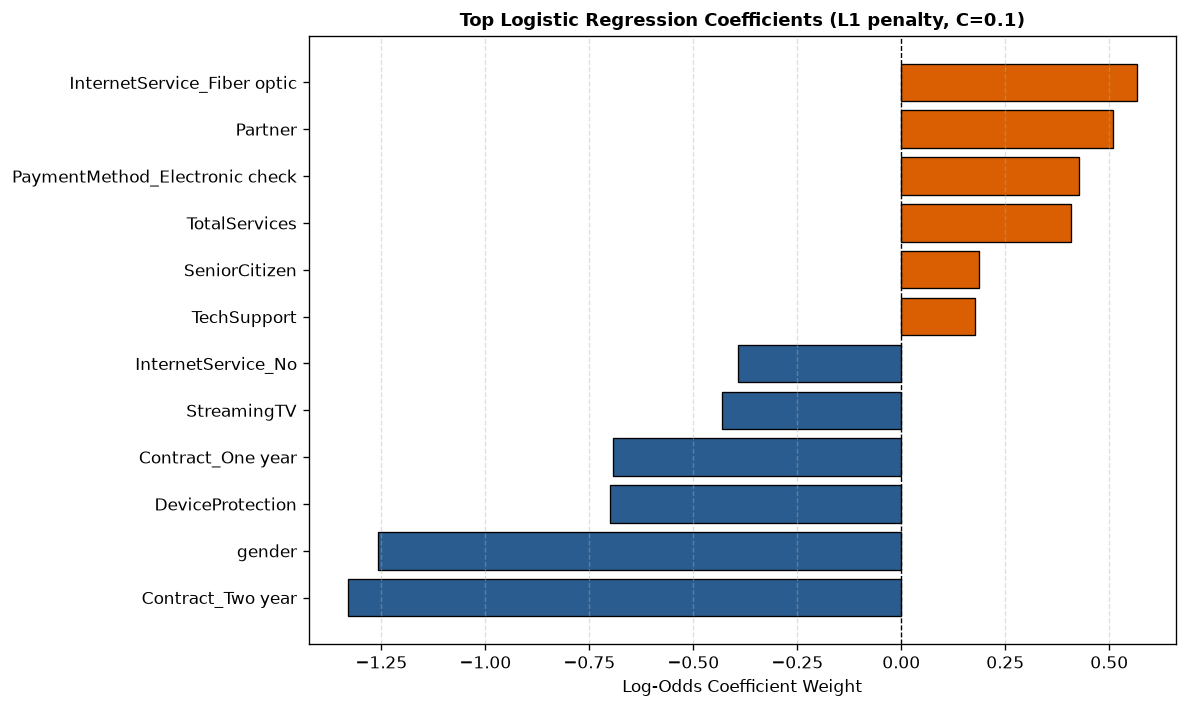

Features zeroed out by L1 penalty (4 of 25):
['PaymentMethod_Mailed check', 'PhoneService', 'PaperlessBilling', 'tenure']


In [12]:
best_lr = search.best_estimator_.named_steps['model']
coefs = pd.Series(best_lr.coef_[0], index=X_train.columns).sort_values()

# Plot Top Churn Drivers
plt.figure(figsize=(10, 6), dpi=120)
top_coefs = pd.concat([coefs.head(6), coefs.tail(6)])
colors = ['#2b5c8f' if x < 0 else '#d95f02' for x in top_coefs.values]

plt.barh(top_coefs.index, top_coefs.values, color=colors, edgecolor='black', linewidth=0.8)
plt.axvline(0, color='black', linestyle='--', linewidth=0.8)
plt.title(f"Top Logistic Regression Coefficients (L1 penalty, C={search.best_params_['model__C']})", fontsize=11, fontweight='bold')
plt.xlabel("Log-Odds Coefficient Weight")
plt.grid(axis='x', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

# Show zeroed-out features due to L1 penalty
zero_features = coefs[coefs == 0].index.tolist()
print(f"Features zeroed out by L1 penalty ({len(zero_features)} of {len(coefs)}):\n{zero_features}")
